In [77]:
import numpy as np
import os
import matplotlib.pyplot as plt
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

In [ ]:
## 1. We used CNN

In [55]:
classifier = Sequential()

In [57]:
classifier.add(Conv2D(32, (3, 3), input_shape=(64, 64, 3), activation="relu"))

In [58]:
classifier.add(MaxPooling2D(pool_size=(2, 2)))

In [59]:
classifier.add(Flatten())


In [60]:
classifier.add(Dense(units=128, activation="relu"))
classifier.add(Dropout(0.5))
classifier.add(Dense(units=1, activation="sigmoid"))

In [61]:
classifier.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
classifier.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 60, 60, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     3,686,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,696,801 (14.10 MB)

 Trainable params: 3,696,801 (14.10 MB)

 Non-trainable params: 0 (0.00 B)

In [63]:
train_datagen = ImageDataGenerator(rescale=1.0/255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
test_datagen = ImageDataGenerator(rescale=1.0/255)

training_set = train_datagen.flow_from_directory("training_data/trainning", target_size=(64,64), batch_size=32, class_mode="binary")
validation_set = test_datagen.flow_from_directory("training_data/validating", target_size=(64,64), batch_size=32, class_mode="binary")

print("Class indices:", training_set.class_indices)

Found 349 images belonging to 2 classes.
Found 100 images belonging to 2 classes.
Class indices: {'damaged': 0, 'intact': 1}


In [64]:
test_set = test_datagen.flow_from_directory("training_data/testing", target_size=(64,64), batch_size=32, class_mode="binary")
loss, accuracy = classifier.evaluate(test_set)
print(f"Test accuracy: {accuracy:.2%}")
print(test_set.samples)
print(test_set.class_indices)

Found 27 images belonging to 2 classes.
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 968ms/step - accuracy: 0.5185 - loss: 0.7025
Test accuracy: 51.85%
27
{'damaged': 0, 'intact': 1}


In [ ]:
## 2. We observed Overfitting

In [65]:
early_stop = EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)

history = classifier.fit(training_set, epochs=30, validation_data=validation_set, callbacks=[early_stop])

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 655ms/step - accuracy: 0.5043 - loss: 1.0884 - val_accuracy: 0.5300 - val_loss: 0.6811
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 599ms/step - accuracy: 0.5415 - loss: 0.6941 - val_accuracy: 0.6300 - val_loss: 0.6681
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 514ms/step - accuracy: 0.5501 - loss: 0.6876 - val_accuracy: 0.6600 - val_loss: 0.6794
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 643ms/step - accuracy: 0.5817 - loss: 0.6839 - val_accuracy: 0.5300 - val_loss: 0.6752
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 568ms/step - accuracy: 0.6504 - loss: 0.6631 - val_accuracy: 0.6200 - val_loss: 0.6625
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 882ms/step - accuracy: 0.6189 - loss: 0.6695 - val_accuracy: 0.7100 - val_loss: 0.6454
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 701ms/step - accuracy: 0.6848 - loss: 0.6394 - val_accuracy: 0.6100 - val_loss: 0.6746
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 706ms/step - accuracy: 0.6390 - loss: 0.6330 - val_accuracy: 0.

In [25]:
classifier.save("box_damage_classifier.keras")
print("Model saved")

Model saved


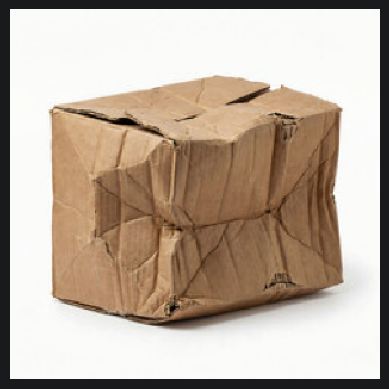

True label: damaged | Predicted: Damaged


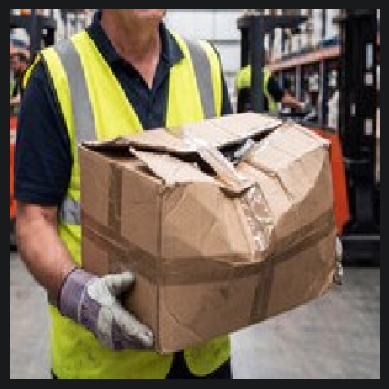

True label: damaged | Predicted: Damaged


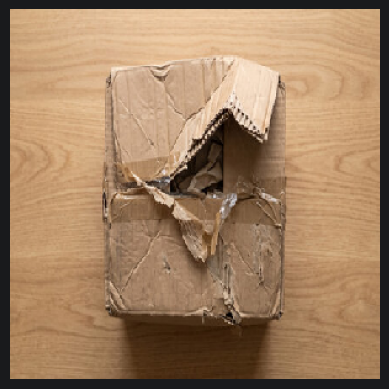

True label: damaged | Predicted: Damaged


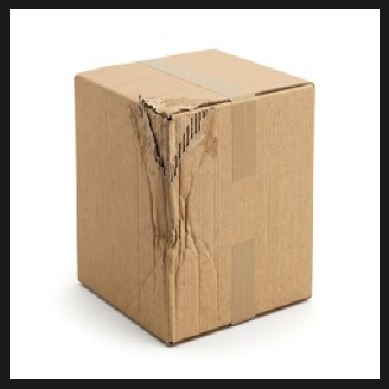

True label: damaged | Predicted: Damaged


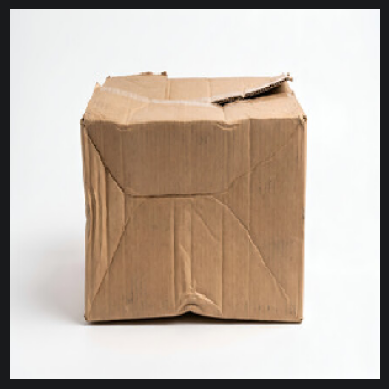

True label: damaged | Predicted: Damaged


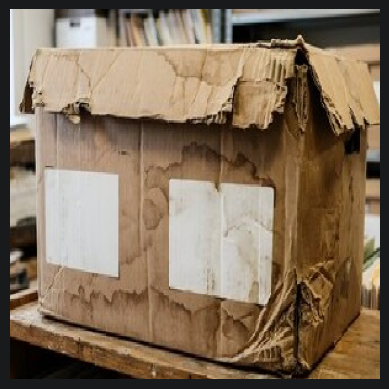

True label: damaged | Predicted: Damaged


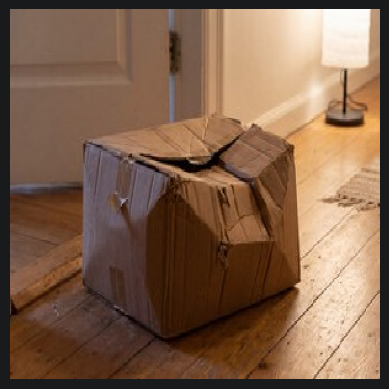

True label: damaged | Predicted: Damaged


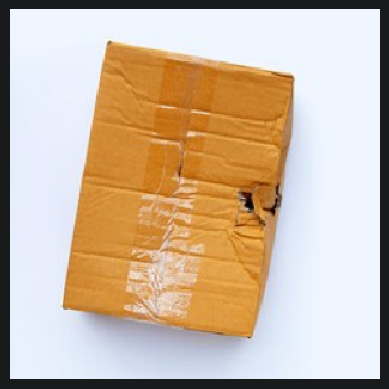

True label: damaged | Predicted: Damaged


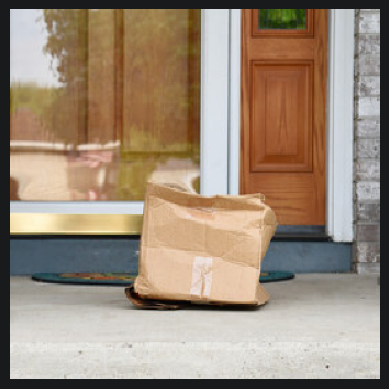

True label: damaged | Predicted: Damaged


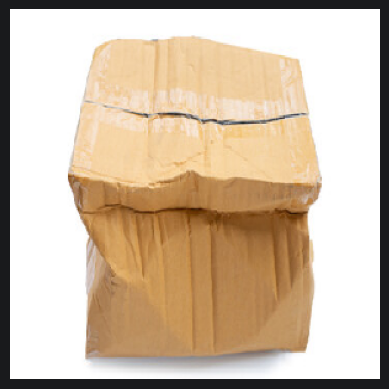

True label: damaged | Predicted: Damaged


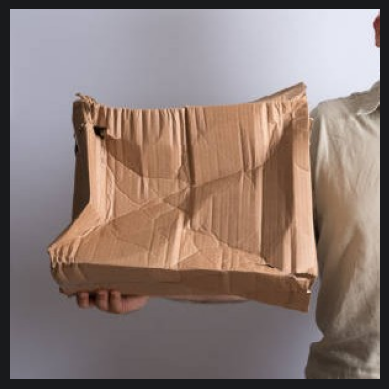

True label: damaged | Predicted: Damaged


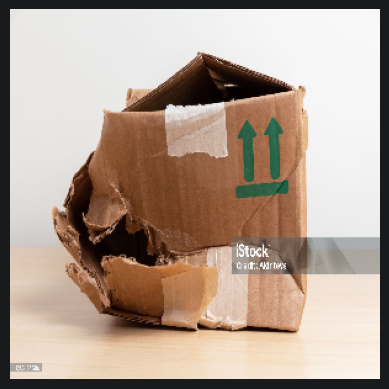

True label: damaged | Predicted: Damaged


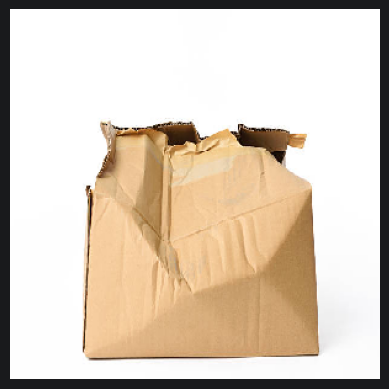

True label: damaged | Predicted: Damaged


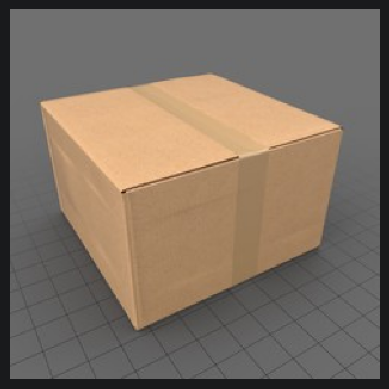

True label: intact | Predicted: Damaged


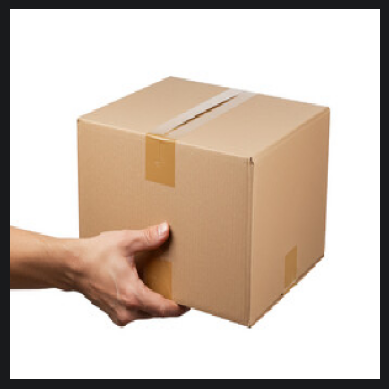

True label: intact | Predicted: Damaged


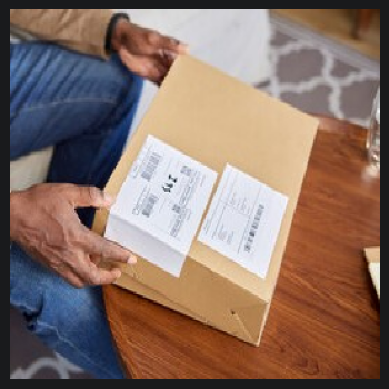

True label: intact | Predicted: Damaged


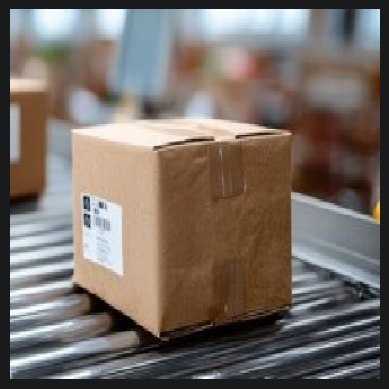

True label: intact | Predicted: Damaged


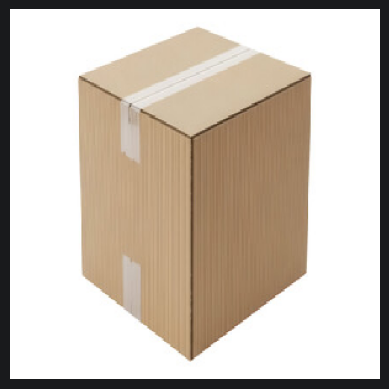

True label: intact | Predicted: Damaged


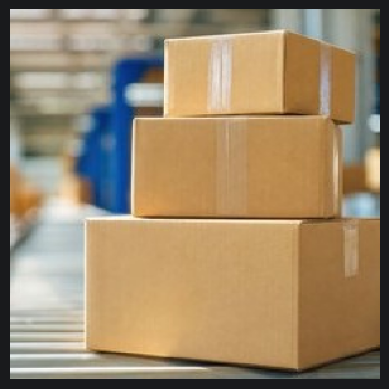

True label: intact | Predicted: Damaged


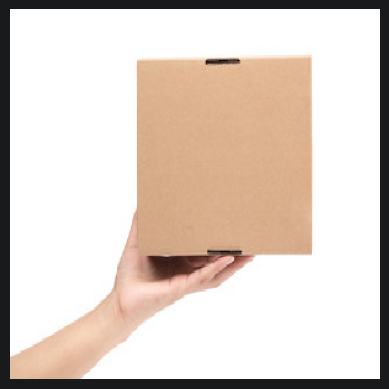

True label: intact | Predicted: Damaged


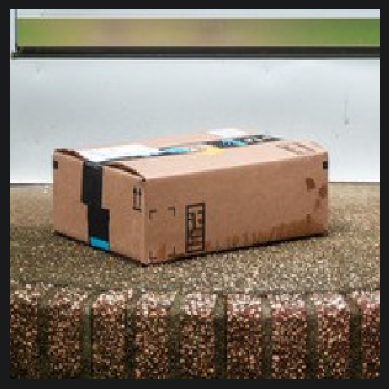

True label: intact | Predicted: Damaged


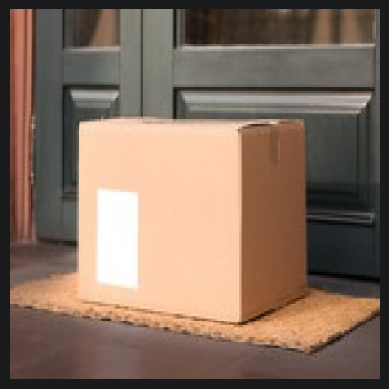

True label: intact | Predicted: Damaged


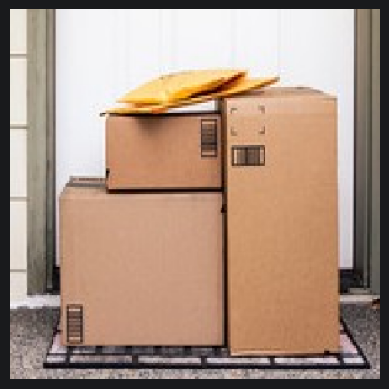

True label: intact | Predicted: Damaged


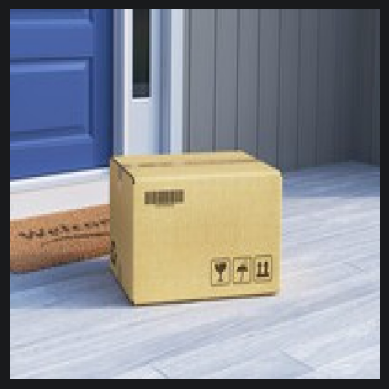

True label: intact | Predicted: Damaged


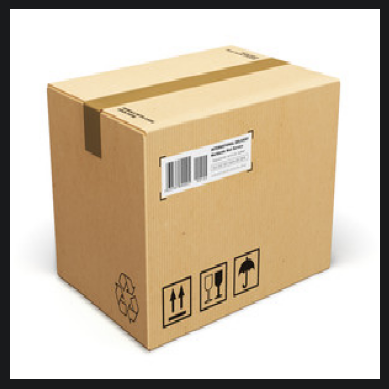

True label: intact | Predicted: Damaged


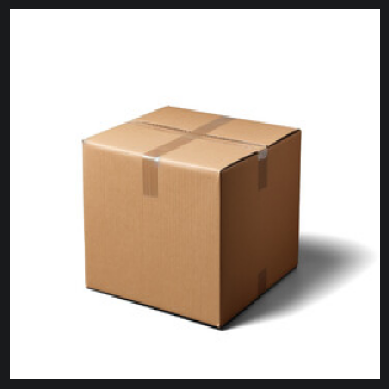

True label: intact | Predicted: Damaged


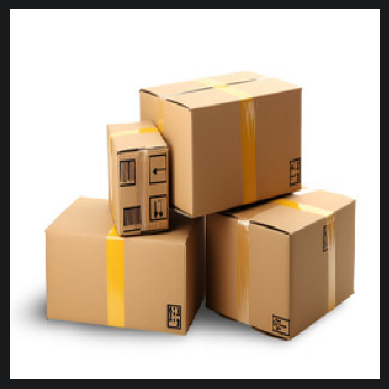

True label: intact | Predicted: Damaged


In [76]:
base_path = 'training_data/testing'

for true_label in ['damaged', 'intact']:
    dir_path = os.path.join(base_path, true_label)
    for i in os.listdir(dir_path):
        if i == '.ipynb_checkpoints':
            continue
        full_path = os.path.join(dir_path, i)

        img = image.load_img(full_path, target_size=(300, 300))
        plt.imshow(img)
        plt.axis('off')
        plt.show()

        model_input = image.load_img(full_path, target_size=(64, 64))
        model_input = image.img_to_array(model_input)
        model_input = np.expand_dims(model_input, axis=0)

        val = classifier.predict(model_input, verbose=0)
        prediction = "Damaged" if val < 0.5 else "Intact"
        print(f"True label: {true_label} | Predicted: {prediction}")


In [ ]:
## 3. Final Model--- Transfer Learning With MobileNetV2

In [70]:
training_set = train_datagen.flow_from_directory("training_data/trainning", target_size=(160,160), batch_size=32, class_mode="binary")
validation_set = test_datagen.flow_from_directory("training_data/validating", target_size=(160,160), batch_size=32, class_mode="binary")
print("Class indices:", training_set.class_indices)

Found 349 images belonging to 2 classes.
Found 100 images belonging to 2 classes.
Class indices: {'damaged': 0, 'intact': 1}


In [71]:
early_stop = EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)
history = classifier.fit(training_set, epochs=30, validation_data=validation_set, callbacks=[early_stop])

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6476 - loss: 0.6919 - val_accuracy: 0.8800 - val_loss: 0.3468
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 860ms/step - accuracy: 0.8854 - loss: 0.2963 - val_accuracy: 0.8700 - val_loss: 0.2942
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.8854 - loss: 0.2830 - val_accuracy: 0.8900 - val_loss: 0.2527
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9226 - loss: 0.2096 - val_accuracy: 0.8900 - val_loss: 0.2297
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9542 - loss: 0.1420 - val_accuracy: 0.9000 - val_loss: 0.2696
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.9570 - loss: 0.1357 - val_accuracy: 0.9000 - val_loss: 0.2345
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9570 - loss: 0.1148 - val_accuracy: 0.9000 - val_loss: 0.2485
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.9427 - loss: 0.1268 - val_accuracy: 0.9100 - val_lo

In [72]:
classifier.save("box_damage_classifier_mobilenet.keras")
print("Model saved")

Model saved


In [73]:
test_set = test_datagen.flow_from_directory("training_data/testing", target_size=(160,160), batch_size=32, class_mode="binary")
loss, accuracy = classifier.evaluate(test_set)
print(f"Test accuracy: {accuracy:.2%}")

Found 27 images belonging to 2 classes.
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 1.0000 - loss: 0.1431
Test accuracy: 100.00%


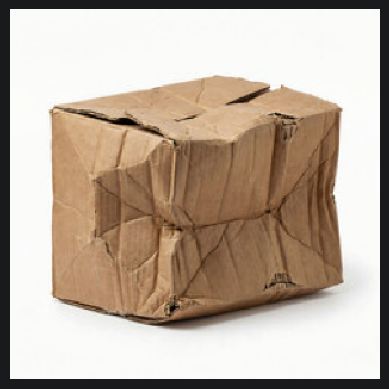

True label: damaged | Predicted: Damaged


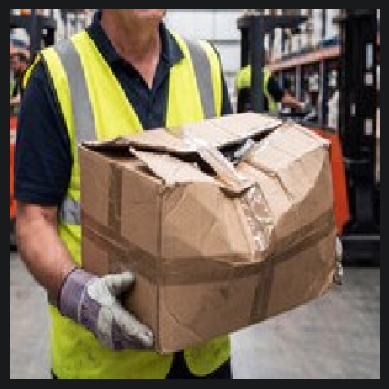

True label: damaged | Predicted: Damaged


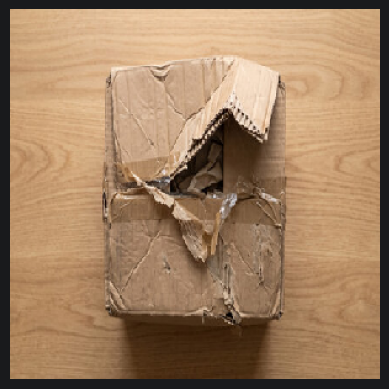

True label: damaged | Predicted: Damaged


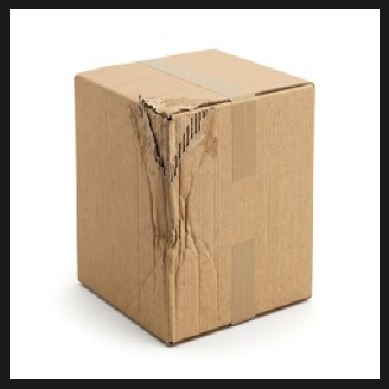

True label: damaged | Predicted: Damaged


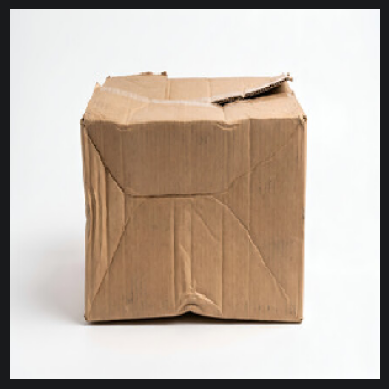

True label: damaged | Predicted: Damaged


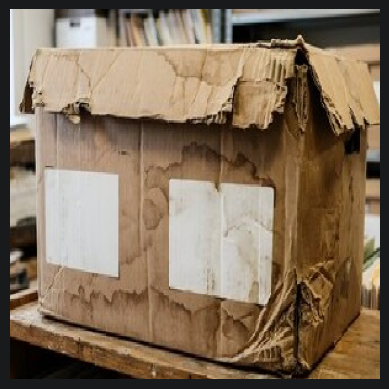

True label: damaged | Predicted: Damaged


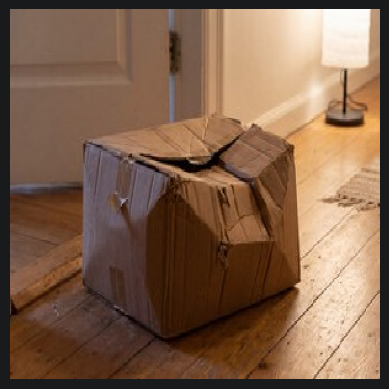

True label: damaged | Predicted: Damaged


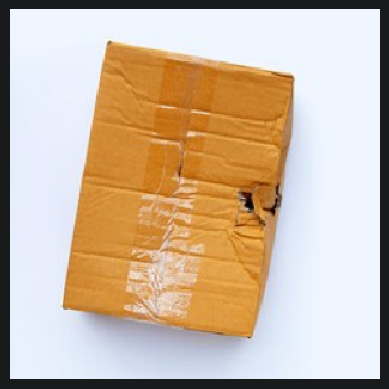

True label: damaged | Predicted: Damaged


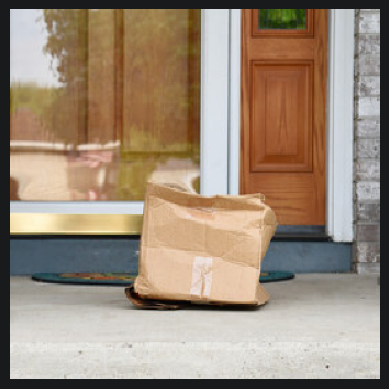

True label: damaged | Predicted: Damaged


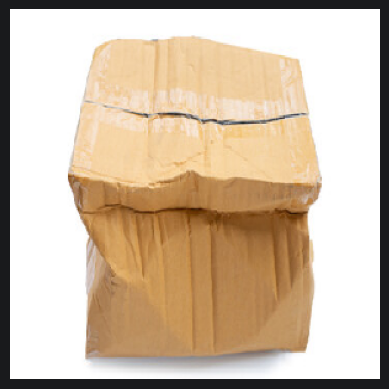

True label: damaged | Predicted: Damaged


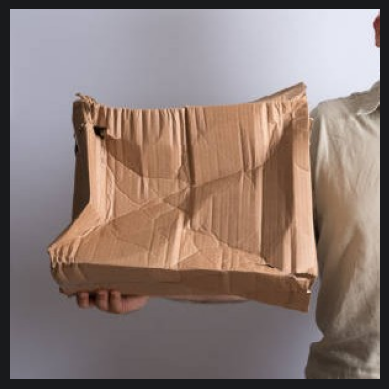

True label: damaged | Predicted: Damaged


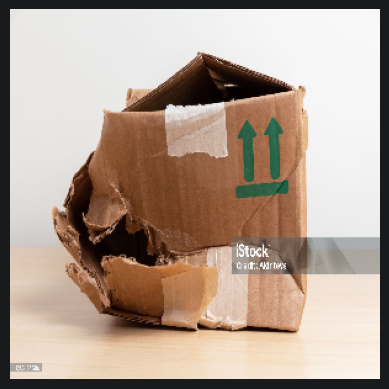

True label: damaged | Predicted: Damaged


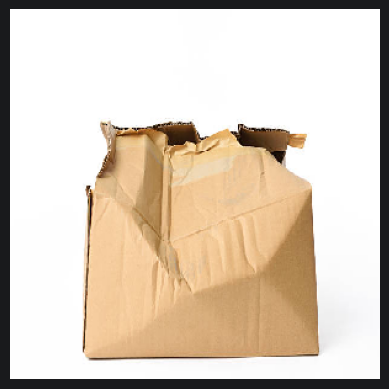

True label: damaged | Predicted: Damaged


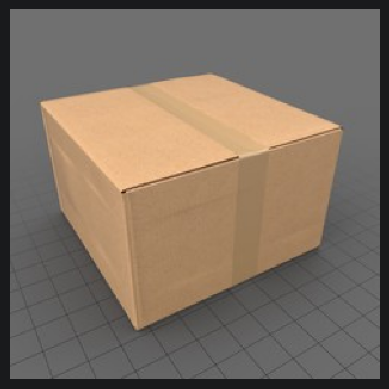

True label: intact | Predicted: Intact


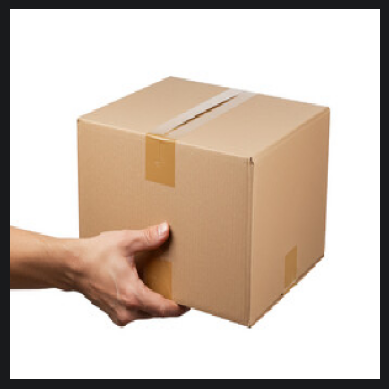

True label: intact | Predicted: Intact


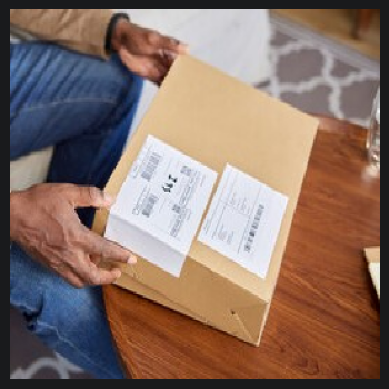

True label: intact | Predicted: Intact


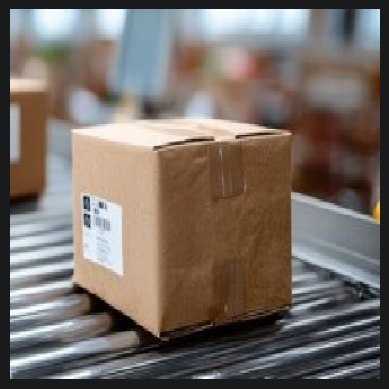

True label: intact | Predicted: Intact


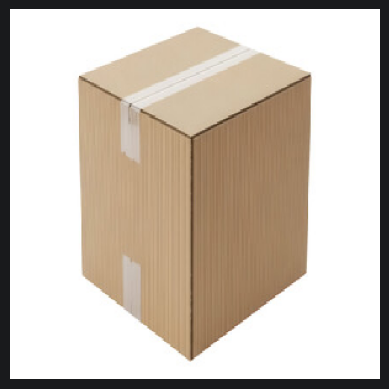

True label: intact | Predicted: Intact


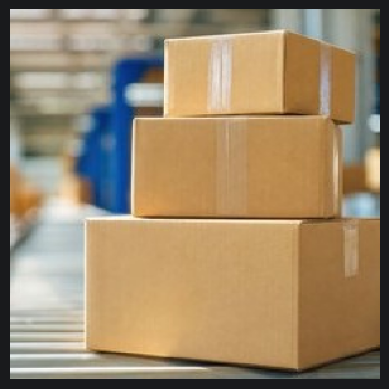

True label: intact | Predicted: Intact


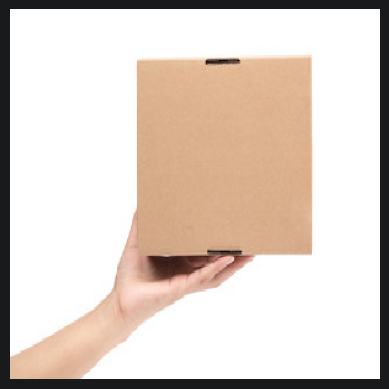

True label: intact | Predicted: Intact


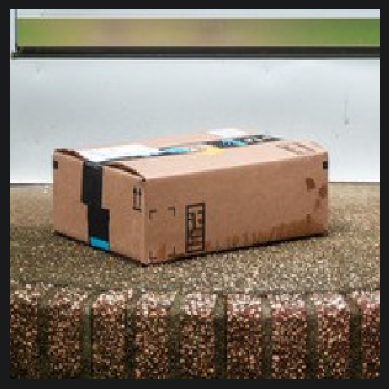

True label: intact | Predicted: Intact


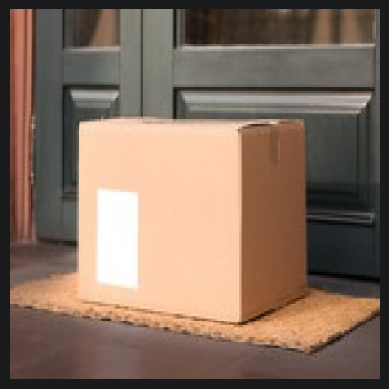

True label: intact | Predicted: Intact


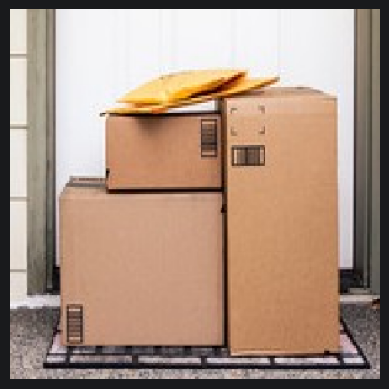

True label: intact | Predicted: Intact


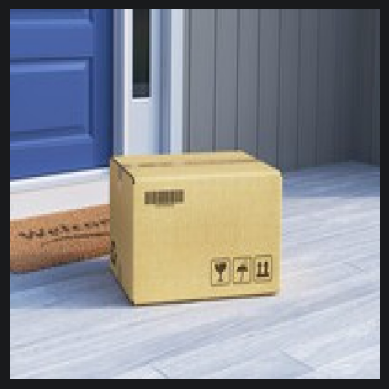

True label: intact | Predicted: Intact


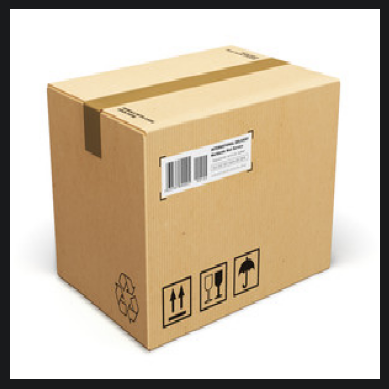

True label: intact | Predicted: Intact


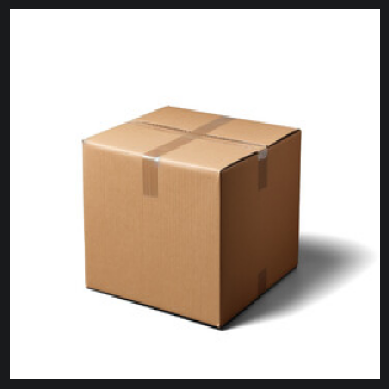

True label: intact | Predicted: Intact


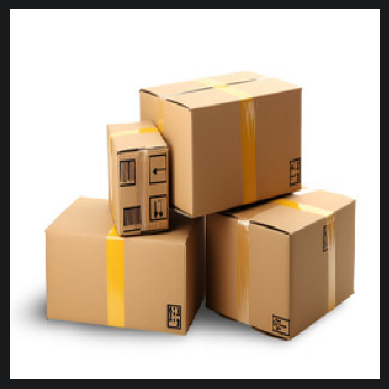

True label: intact | Predicted: Intact


In [78]:
base_path = 'training_data/testing'

for true_label in ['damaged', 'intact']:
    dir_path = os.path.join(base_path, true_label)
    for i in os.listdir(dir_path):
        if i == '.ipynb_checkpoints':
            continue
        full_path = os.path.join(dir_path, i)

        img = image.load_img(full_path, target_size=(300, 300))
        plt.imshow(img)
        plt.axis('off')
        plt.show()

        model_input = image.load_img(full_path, target_size=(160, 160))
        model_input = image.img_to_array(model_input) / 255.0
        model_input = np.expand_dims(model_input, axis=0)

        val = classifier.predict(model_input, verbose=0)
        prediction = "Damaged" if val < 0.5 else "Intact"
        print(f"True label: {true_label} | Predicted: {prediction}")